# RecSys, ДЗ 1
Владислав Мухаметов

Рекомендую пользователю 10 товаров, которые он ещё не оценивал. Положительный отклик — отзыв на 4 или 5 звёзд.

Данные: [Amazon Review Data 2018, Musical Instruments, 5-core](https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/index.html).
`reviewerID` — пользователь, `asin` — товар, `overall` — оценка, `unixReviewTime` — время отзыва.
Из карточек товаров беру бренд и название. Тексты отзывов не использую.

Запуск: Python 3.12, `pip install -r requirements.txt`, открыть ноутбук в Jupyter и **Run → Run All Cells**.
Данные скачаются в `data/`. Для EASE желательно 16 ГБ RAM.
Формулы методов разобраны в [лекциях и семинарах курса](https://github.com/girafe-ai/recsys/tree/26f), темы CF, ALS, EASE и FM.

In [1]:
import gc
import itertools
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

from experiment import (download_data, load_data, split_data, interaction_matrix,
                        item_features, evaluation_users, evaluate)

SEED = 42
K = 10
PRIMARY_METRIC = 'NDCG@10'
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
pd.set_option('display.max_colwidth', 150)
pd.set_option('display.max_rows', 100)
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True, 'grid.alpha': 0.2})

## Данные

Беру всю категорию. Удаляю строки с пропущенными ключами и неверными оценками, затем повторы user–item.
Для повторов оставляю первый отзыв по времени: задача — рекомендовать новый товар, а не повторное взаимодействие.
При совпадении времени сохраняется порядок строк. В метаданных также оставляю первую запись ASIN.

In [2]:
DATA_DIR = Path('data')
download_data(DATA_DIR)
raw, data, metadata, stats = load_data(DATA_DIR)
display(pd.Series(stats, name='count').to_frame())
display(raw.isna().sum().rename('missing').to_frame())
assert 100_000 <= len(data) <= 2_000_000
assert data.user_id.nunique() >= 1000 and data.item_id.nunique() >= 1000
assert not data.duplicated(['user_id', 'item_id']).any()
print('Period:', pd.to_datetime(data.timestamp.min(), unit='s'), '—',
      pd.to_datetime(data.timestamp.max(), unit='s'))
print('Sparsity:', 1 - len(data) / (data.user_id.nunique() * data.item_id.nunique()))
display(data.head().drop(columns='user_id'))

,count
raw_rows,231392
invalid_rows,0
repeated_pairs,12236
clean_rows,219156
users,27530
items,10620
metadata_rows,120310
metadata_duplicate_ids,8175
metadata_nonempty_categories,114397


,missing
user_id,0
item_id,0
rating,0
timestamp,0


Period: 2003-10-28 00:00:00 — 2018-09-28 00:00:00
Sparsity: 0.9992504119799459


,item_id,rating,timestamp
0,B00006HO3L,4.0,1067299200
1,B00001W0DH,3.0,1080345600
2,B00001W0DT,4.0,1086048000
3,B00006HOLL,5.0,1086048000
4,B0002CZVKA,4.0,1090281600


## EDA

Посмотрю на оценки, активность пользователей, популярность товаров и заполненность метаданных.
Дополнительно редкие ID не отбрасываю.

,events_per_user,events_per_item
count,27530.000000,10620.000000
mean,7.960625,20.636158
std,5.890834,58.183222
min,1.000000,1.000000
25%,5.000000,6.000000
50%,6.000000,9.000000
75%,9.000000,18.000000
max,229.000000,1756.000000


,missing_count,missing_fraction
title,9,0.000847
brand,95,0.008945


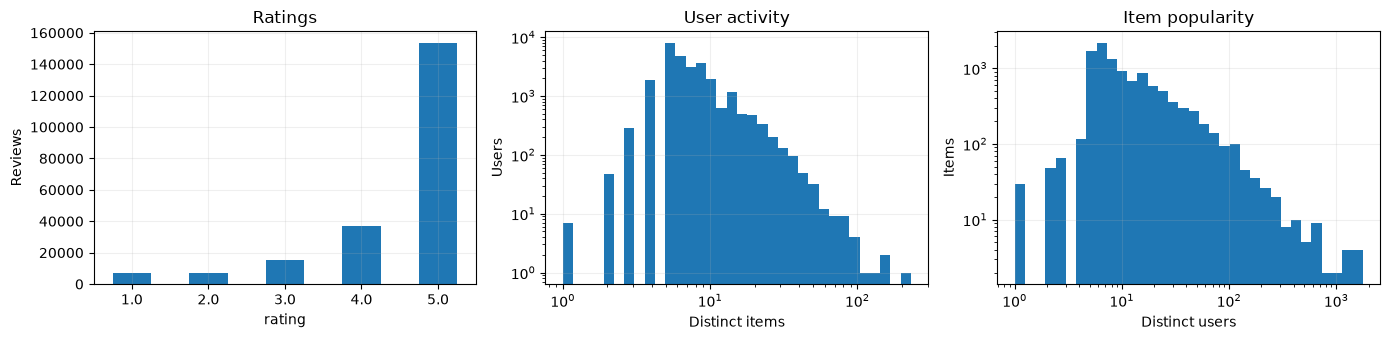

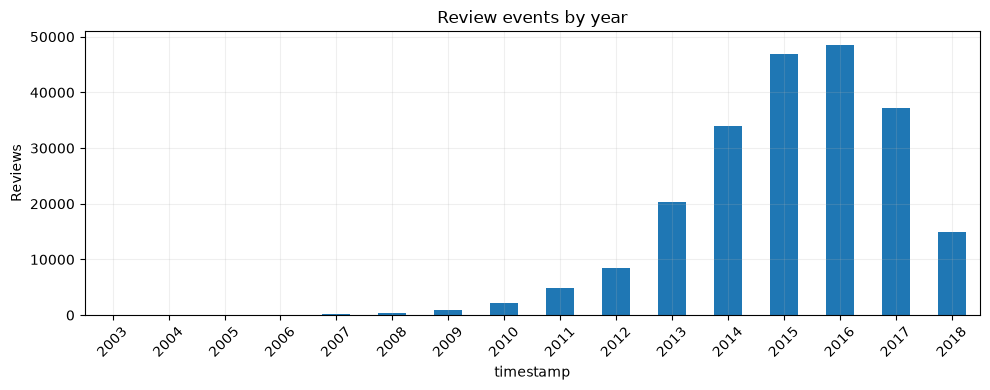

,items
brand,
Fender,421
JIM DUNLOP,252
Behringer,226
Yamaha,176
OnStage,148
Kmise,128
D'Addario Accessories,122
D'Addario,116
Shure,113


In [3]:
activity = data.groupby('user_id').size()
popularity = data.groupby('item_id').size()
display(pd.DataFrame({'events_per_user': activity.describe(), 'events_per_item': popularity.describe()}))
catalog = metadata.reindex(sorted(data.item_id.unique())).fillna('')
display(pd.DataFrame({'missing_count': (catalog == '').sum(),
                      'missing_fraction': (catalog == '').mean()}))
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
data.rating.value_counts().sort_index().plot.bar(ax=axes[0], rot=0, title='Ratings')
axes[0].set_ylabel('Reviews')
axes[1].hist(activity, bins=np.geomspace(1, activity.max() + 1, 35))
axes[1].set(xscale='log', yscale='log', title='User activity', xlabel='Distinct items', ylabel='Users')
axes[2].hist(popularity, bins=np.geomspace(1, popularity.max() + 1, 35))
axes[2].set(xscale='log', yscale='log', title='Item popularity', xlabel='Distinct users', ylabel='Items')
fig.tight_layout(); plt.show()
annual = data.groupby(pd.to_datetime(data.timestamp, unit='s').dt.year).size()
annual.plot.bar(title='Review events by year', ylabel='Reviews', rot=45)
plt.tight_layout(); plt.show()
display(catalog.brand.value_counts().head(12).rename('items').to_frame())